<a href="https://www.kaggle.com/code/djouaheryasmine/baseline?scriptVersionId=307701514" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Multi-Objective NAS Baseline — Pareto Front Search
**Objective**: Maximize accuracy · Minimize latency  
**Search space**: NAS-Bench-201 (15 625 architectures) — **exhaustive**, all architectures evaluated  
**Hardware metrics**: HW-NAS-Bench  
**Accuracy**: NAS-Bench-201 (pre-extracted CSV)


## 0 · Configuration

In [1]:
import numpy as np

# ── Paths ────────────────────────────────────────────────────────────────────
HW_NAS_ROOT   = "/kaggle/input/datasets/djouaheryasmine/hw-nas-bench-main/HW-NAS-Bench-main"
HW_NAS_PICKLE = f"{HW_NAS_ROOT}/HW-NAS-Bench-v1_0.pickle"

NAS201_ROOT   = "/kaggle/input/datasets/djouaheryasmine/nas-bench-201/NAS-Bench-201"
NAS201_PTH    = f"{NAS201_ROOT}/NAS-Bench-201-v1_1-096897.pth"
ACC_CSV       = "/kaggle/input/datasets/djouaheryasmine/nasbench201-accuracies/nasbench201_accuracies.csv"

# ── Search config ─────────────────────────────────────────────────────────────
DATASET       = "cifar10"      # cifar10 | cifar100 | ImageNet16-120
HW_PLATFORM   = "raspi4"       # edgegpu | raspi4 | edgetpu | pixel3 | eyeriss | fpga
SEED          = 42             # for reproducibility (used wherever randomness appears)

# Total NAS-Bench-201 search space size — do NOT change this.
# The exhaustive search always covers all architectures.
SEARCH_SPACE_SIZE = 15_625

np.random.seed(SEED)
print(f"Config: dataset={DATASET}, hw_platform={HW_PLATFORM}, seed={SEED}")
print(f"Exhaustive search over all {SEARCH_SPACE_SIZE} architectures.")

Config: dataset=cifar10, hw_platform=raspi4, seed=42
Exhaustive search over all 15625 architectures.


## 1 · Setup & imports

In [2]:
import sys, os, json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm import tqdm
import time

# Register both API packages
sys.path.insert(0, HW_NAS_ROOT)
sys.path.insert(0, NAS201_ROOT)

plt.style.use("seaborn-v0_8-whitegrid")

print("Python", sys.version)
print("NumPy ", np.__version__)
print("Pandas", pd.__version__)

Python 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
NumPy  2.0.2
Pandas 2.3.3


## 2 · Load HW-NAS-Bench (hardware metrics)

In [3]:
from hw_nas_bench_api import HWNASBenchAPI as HWAPI

hw_api = HWAPI(HW_NAS_PICKLE, search_space="nasbench201")

LATENCY_KEY = f"{HW_PLATFORM}_latency"

# Quick sanity check
sample = hw_api.query_by_index(0, DATASET)
print("Available HW keys:", list(sample.keys()))
assert LATENCY_KEY in sample, (
    f"Key '{LATENCY_KEY}' not found. "
    f"Available keys: {list(sample.keys())}"
)
print(f"Latency key used : '{LATENCY_KEY}'")
print(f"Sample latency   : {sample[LATENCY_KEY]:.4f} ms")

Available HW keys: ['edgegpu_latency', 'edgegpu_energy', 'raspi4_latency', 'edgetpu_latency', 'pixel3_latency', 'eyeriss_latency', 'eyeriss_energy', 'eyeriss_arithmetic_intensity', 'fpga_latency', 'fpga_energy', 'average_hw_metric']
Latency key used : 'raspi4_latency'
Sample latency   : 10.4820 ms


## 3 · Load accuracy lookup (pre-extracted CSV)

In [4]:
acc_df = pd.read_csv(ACC_CSV).set_index("arch_index")

ACC_COL = f"acc_{DATASET}"
assert ACC_COL in acc_df.columns, (
    f"Column '{ACC_COL}' not found. Available: {list(acc_df.columns)}"
)

print(f"Accuracy table : {acc_df.shape[0]} architectures × {acc_df.shape[1]} datasets")
print(acc_df.head())


def get_accuracy(arch_index: int) -> float:
    """Returns test accuracy (%) for the configured dataset."""
    return float(acc_df.loc[arch_index, ACC_COL])


def get_latency(arch_index: int) -> float:
    """Returns latency (ms) for the configured platform and dataset."""
    return float(hw_api.query_by_index(arch_index, DATASET)[LATENCY_KEY])


print(f"\nArch 0 — accuracy: {get_accuracy(0):.2f}%  latency: {get_latency(0):.4f} ms")

Accuracy table : 15625 architectures × 3 datasets
            acc_cifar10  acc_cifar100  acc_ImageNet16-120
arch_index                                               
0                 81.90         51.98           25.766667
1                 90.63         69.68           45.433333
2                 81.93         55.24           26.700000
3                 83.78         58.22           28.133333
4                 84.44         59.98           31.200000

Arch 0 — accuracy: 81.90%  latency: 10.4820 ms


## 4 · Exhaustive search

Every architecture in the NAS-Bench-201 search space is evaluated.
Accuracy is an instant CSV lookup; latency is a pickle query (~80 k arch/s on Kaggle).

In [6]:
start_time = time.time()  # record start
results = []

for idx in tqdm(range(SEARCH_SPACE_SIZE), desc="Exhaustive search — all architectures"):
    results.append({
        "arch_index" : idx,
        "accuracy"   : get_accuracy(idx),   # instant — CSV lookup
        "latency"    : get_latency(idx),     # pickle lookup
    })

df = pd.DataFrame(results)

assert len(df) == SEARCH_SPACE_SIZE, (
    f"Expected {SEARCH_SPACE_SIZE} rows, got {len(df)}"
)

end_time = time.time()  # record end
elapsed = end_time - start_time
print(f"Time taken: {elapsed:.4f} seconds")

print(f"\nEvaluated : {len(df)} / {SEARCH_SPACE_SIZE} architectures (100%)")
print(f"Accuracy  : {df['accuracy'].min():.2f}% – {df['accuracy'].max():.2f}%")
print(f"Latency   : {df['latency'].min():.4f} – {df['latency'].max():.4f} ms")

Exhaustive search — all architectures: 100%|██████████| 15625/15625 [00:00<00:00, 59357.53it/s]

Time taken: 0.2845 seconds

Evaluated : 15625 / 15625 architectures (100%)
Accuracy  : 10.00% – 91.49%
Latency   : 0.0113 – 98.8875 ms


In [7]:
# ─────────────────────────────────────────────
# Select BEST architecture from exhaustive search
# ─────────────────────────────────────────────

import numpy as np

# 1. Normalize
def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

start_time = time.time()  

df["acc_norm"] = normalize(df["accuracy"])
df["lat_norm"] = normalize(df["latency"])

# 2. Trade-off parameter
alpha = 0.5   # change this if needed

# 3. Score (maximize accuracy, minimize latency)
df["score"] = alpha * df["acc_norm"] - (1 - alpha) * df["lat_norm"]

# 4. Select best
best = df.loc[df["score"].idxmax()]
end_time = time.time()  # record end
elapsed = end_time - start_time
print(f"Time taken: {elapsed:.4f} seconds")

print("\n BEST ARCHITECTURE (EXHAUSTIVE SEARCH)")
print(f"Index    : {best['arch_index']}")
print(f"Accuracy : {best['accuracy']:.4f}")
print(f"Latency  : {best['latency']:.4f}")
print(f"Score    : {best['score']:.4f}")

Time taken: 0.0065 seconds

 BEST ARCHITECTURE (EXHAUSTIVE SEARCH)
Index    : 2649.0
Accuracy : 87.2400
Latency  : 5.2035
Score    : 0.4477


## 5 · Pareto front computation

In [8]:
def compute_pareto_front(df: pd.DataFrame) -> pd.DataFrame:
    """
    Returns the Pareto-optimal subset of df.

    Objectives: maximize accuracy, minimize latency.
    A solution i is dominated if there exists j such that:
        acc[j] >= acc[i]  AND  lat[j] <= lat[i]
        with at least one strict inequality.

    Complexity: O(n²) via NumPy broadcasting — fast enough for n=15 625.
    """
    pareto_mask = np.ones(len(df), dtype=bool)
    acc = df["accuracy"].values
    lat = df["latency"].values

    for i in range(len(df)):
        if not pareto_mask[i]:
            continue
        dominated = (
            (acc >= acc[i]) & (lat <= lat[i]) &
            ((acc > acc[i]) | (lat < lat[i]))
        )
        dominated[i] = False   # a solution cannot dominate itself
        if dominated.any():
            pareto_mask[i] = False

    return (
        df[pareto_mask]
        .sort_values("accuracy", ascending=False)
        .reset_index(drop=True)
    )


def hypervolume_2d(pareto_df: pd.DataFrame, ref_point: tuple) -> float:
    """
    Computes the 2-D hypervolume indicator.

    Parameters
    ----------
    pareto_df : DataFrame with columns 'accuracy' and 'latency'
    ref_point : (ref_latency, ref_accuracy) — must be worse than every
                Pareto point (higher latency, lower accuracy).

    Returns
    -------
    float — hypervolume indicator (higher is better)
    """
    ref_lat, ref_acc = ref_point

    # Use explicit column names — never rely on positional indices.
    pts = (
        pareto_df[["accuracy", "latency"]]
        .sort_values("latency")   # sweep left-to-right in latency
        .values
    )

    hv = 0.0
    prev_lat = ref_lat
    for acc, lat in pts:
        if acc > ref_acc and lat < prev_lat:
            hv += (prev_lat - lat) * (acc - ref_acc)
            prev_lat = lat
    return hv

start_time = time.time()  # record start

pareto_df = compute_pareto_front(df)

end_time = time.time()  # record end
elapsed = end_time - start_time
print(f"Time taken: {elapsed:.4f} seconds")

print(f"Pareto front size : {len(pareto_df)} / {len(df)} evaluated")
print(f"Best accuracy     : {pareto_df['accuracy'].max():.2f}%")
print(f"Best latency      : {pareto_df['latency'].min():.4f} ms")
print(pareto_df.to_string(index=False))

Time taken: 0.4397 seconds
Pareto front size : 43 / 15625 evaluated
Best accuracy     : 91.49%
Best latency      : 0.0113 ms
 arch_index  accuracy   latency  acc_norm  lat_norm    score
       9930     91.49 80.400089  1.000000  0.813025 0.093488
       1459     91.46 59.089967  0.999632  0.597501 0.201065
      10676     91.41 56.811427  0.999018  0.574457 0.212281
      11400     91.40 53.863263  0.998896  0.544640 0.227128
      14174     91.38 53.840091  0.998650  0.544406 0.227122
       5111     91.29 41.756905  0.997546  0.422201 0.287672
      12466     91.13 36.995618  0.995582  0.374047 0.310768
       4099     90.98 34.807826  0.993742  0.351920 0.320911
       6999     90.90 34.005279  0.992760  0.343803 0.324478
      12451     90.88 31.439525  0.992514  0.317854 0.337330
       6925     90.82 24.372274  0.991778  0.246379 0.372700
       2952     90.68 22.011088  0.990060  0.222498 0.383781
       4627     90.60 21.603181  0.989078  0.218373 0.385353
      15459     90.48

## 6 · Hypervolume indicator

In [9]:
# Reference point: slightly worse than the worst solution on each axis
ref_lat = df["latency"].max()  * 1.1
ref_acc = df["accuracy"].min() * 0.9

hv = hypervolume_2d(pareto_df, ref_point=(ref_lat, ref_acc))
print(f"Hypervolume (ref=({ref_lat:.2f} ms, {ref_acc:.2f}%)) : {hv:.4f}")

Hypervolume (ref=(108.78 ms, 9.00%)) : 108.7650


## 7 · Visualisation

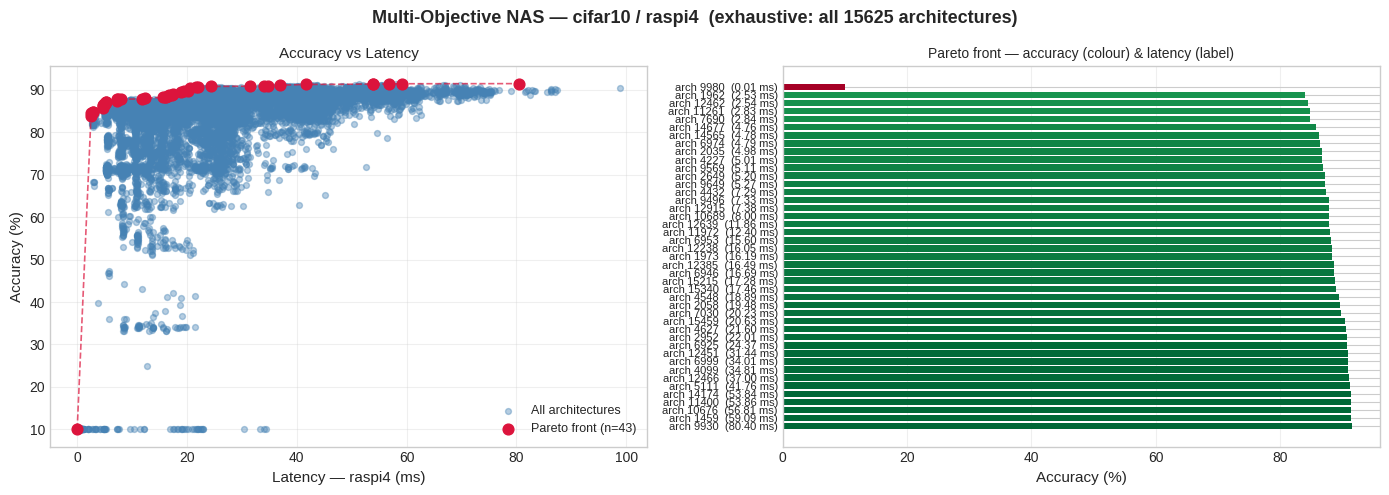

Plot saved to /kaggle/working/pareto_front.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    f"Multi-Objective NAS — {DATASET} / {HW_PLATFORM}  "
    f"(exhaustive: all {SEARCH_SPACE_SIZE} architectures)",
    fontsize=13, fontweight="bold"
)

# ── Left: scatter plot ───────────────────────────────────────────────────────
ax = axes[0]
ax.scatter(
    df["latency"], df["accuracy"],
    s=18, alpha=0.4, color="steelblue", label="All architectures"
)
ax.scatter(
    pareto_df["latency"], pareto_df["accuracy"],
    s=60, color="crimson", zorder=5, label=f"Pareto front (n={len(pareto_df)})"
)
pareto_sorted = pareto_df.sort_values("latency")
ax.plot(
    pareto_sorted["latency"], pareto_sorted["accuracy"],
    color="crimson", linewidth=1.2, linestyle="--", alpha=0.7
)
ax.set_xlabel(f"Latency — {HW_PLATFORM} (ms)", fontsize=11)
ax.set_ylabel("Accuracy (%)", fontsize=11)
ax.set_title("Accuracy vs Latency", fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ── Right: Pareto front details ───────────────────────────────────────────────
ax2 = axes[1]
acc_range = pareto_df["accuracy"].max() - pareto_df["accuracy"].min() + 1e-9
colors = plt.cm.RdYlGn(
    (pareto_df["accuracy"] - pareto_df["accuracy"].min()) / acc_range
)
ax2.barh(range(len(pareto_df)), pareto_df["accuracy"], color=colors)
ax2.set_yticks(range(len(pareto_df)))
ax2.set_yticklabels(
    [f"arch {int(r['arch_index'])}  ({r['latency']:.2f} ms)"
     for _, r in pareto_df.iterrows()],
    fontsize=8
)
ax2.set_xlabel("Accuracy (%)", fontsize=11)
ax2.set_title("Pareto front — accuracy (colour) & latency (label)", fontsize=10)
ax2.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
os.makedirs("/kaggle/working", exist_ok=True)
plt.savefig("/kaggle/working/pareto_front.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved to /kaggle/working/pareto_front.png")

## 8 · Save results

In [11]:
# Save full exhaustive search results
df.to_csv("/kaggle/working/search_results.csv", index=False)

# Save Pareto front
pareto_df.to_csv("/kaggle/working/pareto_front.csv", index=False)

# Save summary JSON
summary = {
    "config": {
        "dataset"            : DATASET,
        "hw_platform"        : HW_PLATFORM,
        "search_space_size"  : SEARCH_SPACE_SIZE,
        "search_type"        : "exhaustive",
        "seed"               : SEED,
    },
    "stats": {
        "pareto_size"   : int(len(pareto_df)),
        "best_accuracy" : float(pareto_df["accuracy"].max()),
        "best_latency"  : float(pareto_df["latency"].min()),
        "hypervolume"   : float(hv),
    },
    "pareto_front": pareto_df.to_dict(orient="records"),
}

with open("/kaggle/working/summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:")
print("  /kaggle/working/search_results.csv")
print("  /kaggle/working/pareto_front.csv")
print("  /kaggle/working/pareto_front.png")
print("  /kaggle/working/summary.json")
print()
print("=" * 40)
print("SUMMARY")
print("=" * 40)
for k, v in summary["stats"].items():
    print(f"  {k:<18}: {v}")

Saved:
  /kaggle/working/search_results.csv
  /kaggle/working/pareto_front.csv
  /kaggle/working/pareto_front.png
  /kaggle/working/summary.json

SUMMARY
  pareto_size       : 43
  best_accuracy     : 91.49
  best_latency      : 0.011283500061836094
  hypervolume       : 108.7649895999348


In [12]:
# ─────────────────────────────────────────────
#  Select BEST architecture using Distance to Ideal Point
# ─────────────────────────────────────────────

import numpy as np
import time


# 1. Normalize (important!)
def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

start_time = time.time() 
df["acc_norm"] = normalize(df["accuracy"])
df["lat_norm"] = normalize(df["latency"])

# 2. Define ideal point

ideal_acc = max(df["acc_norm"])
ideal_lat = min(df["lat_norm"])

# 3. Compute distance to ideal point
df["distance_to_ideal"] = np.sqrt(
    (df["acc_norm"] - ideal_acc) ** 2 +
    (df["lat_norm"] - ideal_lat) ** 2
)

# 4. Select best (minimum distance)
best = df.loc[df["distance_to_ideal"].idxmin()]

end_time = time.time()  # record end
elapsed = end_time - start_time
print(f"Time taken: {elapsed:.4f} seconds")

print("\n BEST ARCHITECTURE (Distance to Ideal Point)")
print(f"Index    : {best['arch_index']}")
print(f"Accuracy : {best['accuracy']:.4f}")
print(f"Latency  : {best['latency']:.4f}")
print(f"Distance : {best['distance_to_ideal']:.6f}")

# 5. Show top 10 closest architectures
print("\n Top 10 closest to ideal:")
display(df.sort_values(by="distance_to_ideal").head(10))

Time taken: 0.0085 seconds

 BEST ARCHITECTURE (Distance to Ideal Point)
Index    : 2649.0
Accuracy : 87.2400
Latency  : 5.2035
Distance : 0.074010

 Top 10 closest to ideal:


,arch_index,accuracy,latency,acc_norm,lat_norm,score,distance_to_ideal
2649,2649,87.24,5.203499,0.947846,0.052512,0.447667,0.074010
9649,9649,87.25,5.269994,0.947969,0.053185,0.447392,0.074403
9569,9569,86.86,5.107180,0.943183,0.051538,0.445823,0.076709
296,296,86.85,5.163324,0.943060,0.052106,0.445477,0.077182
1147,1147,86.90,5.229909,0.943674,0.052779,0.445447,0.077190
1416,1416,86.85,5.203409,0.943060,0.052511,0.445275,0.077457
4227,4227,86.71,5.014174,0.941342,0.050598,0.445372,0.077465
2035,2035,86.66,4.984099,0.940729,0.050293,0.445218,0.077733
12358,12358,86.64,5.015179,0.940483,0.050608,0.444938,0.078124
9654,9654,86.71,5.120729,0.941342,0.051675,0.444834,0.078173
